# Exploratory Data Analysis (EDA): Student Academic Performance (`students_50.xlsx`)

**Objective:** Perform a comprehensive exploratory data analysis on the 50-student academic dataset (`students_50.xlsx`) covering demographic distribution (Age, Field), curriculum breadth (Subjects), assessment components (Internal Marks out of 40, External Marks out of 60, Overall Marks out of 100), correlation structures, and statistical hypothesis testing.

---

## 1. Environment Setup & Data Loading
We begin by importing core Python data science libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`) and inspecting the raw Excel workbook structure.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load Excel workbook and inspect sheet names
xls = pd.ExcelFile('students_50.xlsx')
print('Sheet names:', xls.sheet_names)

df_raw = pd.read_excel('students_50.xlsx', sheet_name='Students')
print('Raw Shape:', df_raw.shape)
df_raw.head()

Sheet names: ['Students']
Raw Shape: (50, 9)
     Name  Age  Field            Subject  Internal Marks (out of 40)  External Marks (out of 60)  Overall Marks  Unnamed: 7  Note: Student data is sample data generated randomly (seed 42). Overall Marks = Internal + External.
0   Aarav   18    BBA          Marketing                          28                          37             65         NaN                                                                                                   NaN
1   Priya   19    BCA  Operating Systems                          23                          51             74         NaN                                                                                                   NaN
2   Rohan   22    BBA          Marketing                          38                          43             81         NaN                                                                                                   NaN
3   Sneha   18    BCA             Python           

## 2. Data Cleaning, Validation & Feature Engineering
Inspection reveals two trailing metadata/empty columns (`Unnamed: 7` and a header note string) containing 100% null values. We drop these artifacts, validate that `Overall Marks == Internal Marks + External Marks` across all 50 records, check for duplicates, and engineer normalized percentage features (`Internal_Pct`, `External_Pct`) alongside academic grade tiers.

In [ ]:
# Retain the 7 core analytical columns
core_cols = [
    'Name', 'Age', 'Field', 'Subject',
    'Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks'
]
df = df_raw[core_cols].copy()

# Data integrity checks
assert df.isnull().sum().sum() == 0, 'Unexpected missing values found!'
assert df.duplicated().sum() == 0, 'Duplicate rows found!'
assert (df['Internal Marks (out of 40)'] + df['External Marks (out of 60)'] == df['Overall Marks']).all(), 'Summation mismatch!'

# Feature engineering: normalized percentages & grade tiers
df['Internal_Pct'] = (df['Internal Marks (out of 40)'] / 40.0 * 100).round(2)
df['External_Pct'] = (df['External Marks (out of 60)'] / 60.0 * 100).round(2)
df['Pct_Gap'] = (df['Internal_Pct'] - df['External_Pct']).round(2)

def assign_grade(m):
    if m >= 90: return 'A+'
    elif m >= 80: return 'A'
    elif m >= 70: return 'B'
    elif m >= 60: return 'C'
    else: return 'D'

df['Grade'] = df['Overall Marks'].apply(assign_grade)
print('Data integrity verified: 50 clean records, 0 nulls, 0 duplicates, 100% arithmetic consistency.')
df.head()

Data integrity verified: 50 clean records, 0 nulls, 0 duplicates, 100% arithmetic consistency.
     Name  Age Field            Subject  Internal Marks (out of 40)  External Marks (out of 60)  Overall Marks  Internal_Pct  External_Pct  Pct_Gap Grade
0   Aarav   18   BBA          Marketing                          28                          37             65          70.0         61.67     8.33     C
1   Priya   19   BCA  Operating Systems                          23                          51             74          57.5         85.00   -27.50     B
2   Rohan   22   BBA          Marketing                          38                          43             81          95.0         71.67    23.33     A
3   Sneha   18   BCA             Python                          26                          37             63          65.0         61.67     3.33     C
4   Karan   22   BBA          Marketing                          37                          36             73          92.5         60

## 3. Descriptive Summary Statistics
Examining central tendency, dispersion, and quartiles across numerical scores and categorical dimensions.

In [ ]:
num_cols = ['Age', 'Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks', 'Internal_Pct', 'External_Pct']
summary_stats = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats['median'] = df[num_cols].median()
summary_stats['iqr'] = summary_stats['75%'] - summary_stats['25%']
print(summary_stats.round(2))

                            count   mean    std   min    25%    50%    75%    max  median    iqr
Age                          50.0  20.68   1.66  18.0  19.00  21.00  22.00   23.0   21.00   3.00
Internal Marks (out of 40)   50.0  30.32   6.05  21.0  26.00  29.50  36.00   40.0   29.50  10.00
External Marks (out of 60)   50.0  44.30   9.22  30.0  37.00  43.00  53.00   60.0   43.00  16.00
Overall Marks                50.0  74.62  10.91  53.0  65.25  74.00  80.75   95.0   74.00  15.50
Internal_Pct                 50.0  75.80  15.11  52.5  65.00  73.75  90.00  100.0   73.75  25.00
External_Pct                 50.0  73.83  15.36  50.0  61.67  71.67  88.33  100.0   71.67  26.67

## 4. Cohort Composition & Grade Distribution
- **Enrollment Split:** BBA leads enrollment with 23 students (46%), followed by BCA with 16 students (32%) and BTech with 11 students (22%).
- **Grade Breakdown:** 100% of students pass (>=50 marks). Grade **B (70–79)** is the modal tier (18 students, 36%), while **32% (16 students)** achieve distinction (**A or A+**). Only 3 students (6%) fall into Grade D (<60).

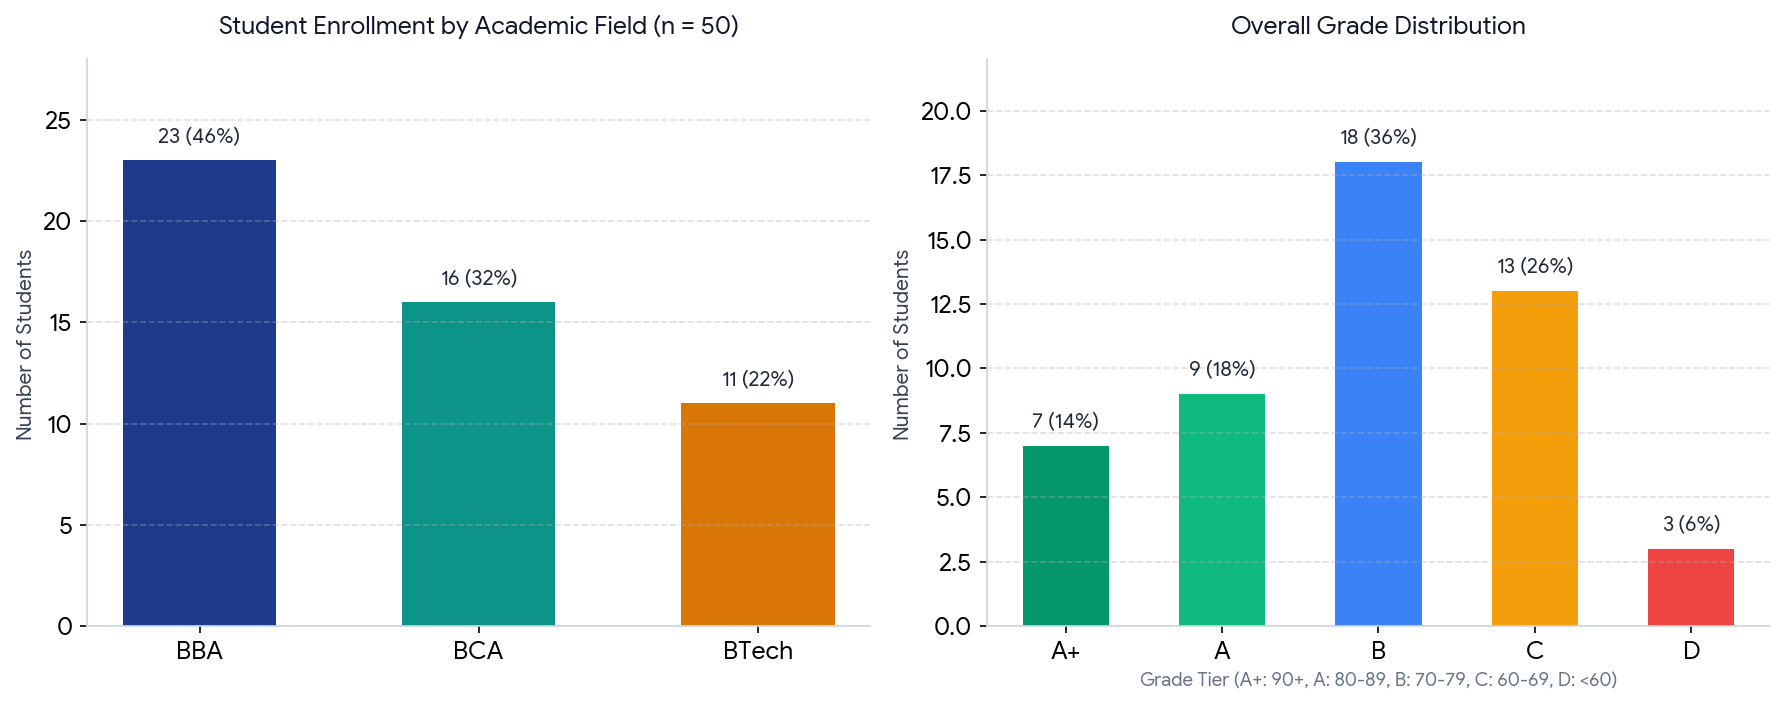

In [ ]:
PALETTE = {'BBA': '#1E3A8A', 'BCA': '#0D9488', 'BTech': '#D97706'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

field_counts = df['Field'].value_counts()
bars = axes[0].bar(field_counts.index, field_counts.values, color=[PALETTE[f] for f in field_counts.index], width=0.55)
axes[0].set_title('Student Enrollment by Academic Field (n = 50)', fontweight='bold')
axes[0].set_ylabel('Number of Students')
axes[0].set_ylim(0, 28)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'{int(h)} ({h/50*100:.0f}%)', ha='center', fontweight='bold')

grade_order = ['A+', 'A', 'B', 'C', 'D']
grade_counts = df['Grade'].value_counts().reindex(grade_order, fill_value=0)
bars2 = axes[1].bar(grade_counts.index, grade_counts.values, color=['#059669', '#10B981', '#3B82F6', '#F59E0B', '#EF4444'], width=0.55)
axes[1].set_title('Overall Grade Distribution', fontweight='bold')
axes[1].set_ylabel('Number of Students')
axes[1].set_ylim(0, 22)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{int(h)} ({h/50*100:.0f}%)', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Assessment Score Distributions
- **Internal Marks (out of 40):** Mean = 30.32 (75.8%), Median = 29.5, Range = 21–40. Uniform/broad spread typical of bounded random generation.
- **External Marks (out of 60):** Mean = 44.30 (73.8%), Median = 43.0, Range = 30–60.
- **Overall Marks (out of 100):** Mean = 74.62, Median = 74.0, SD = 10.91. Because `Overall = Internal + External` (sum of two independent uniform-like variables), Overall Marks converges toward a bell-shaped distribution (Shapiro-Wilk $W = 0.9738, p = 0.3271$, confirming normality).

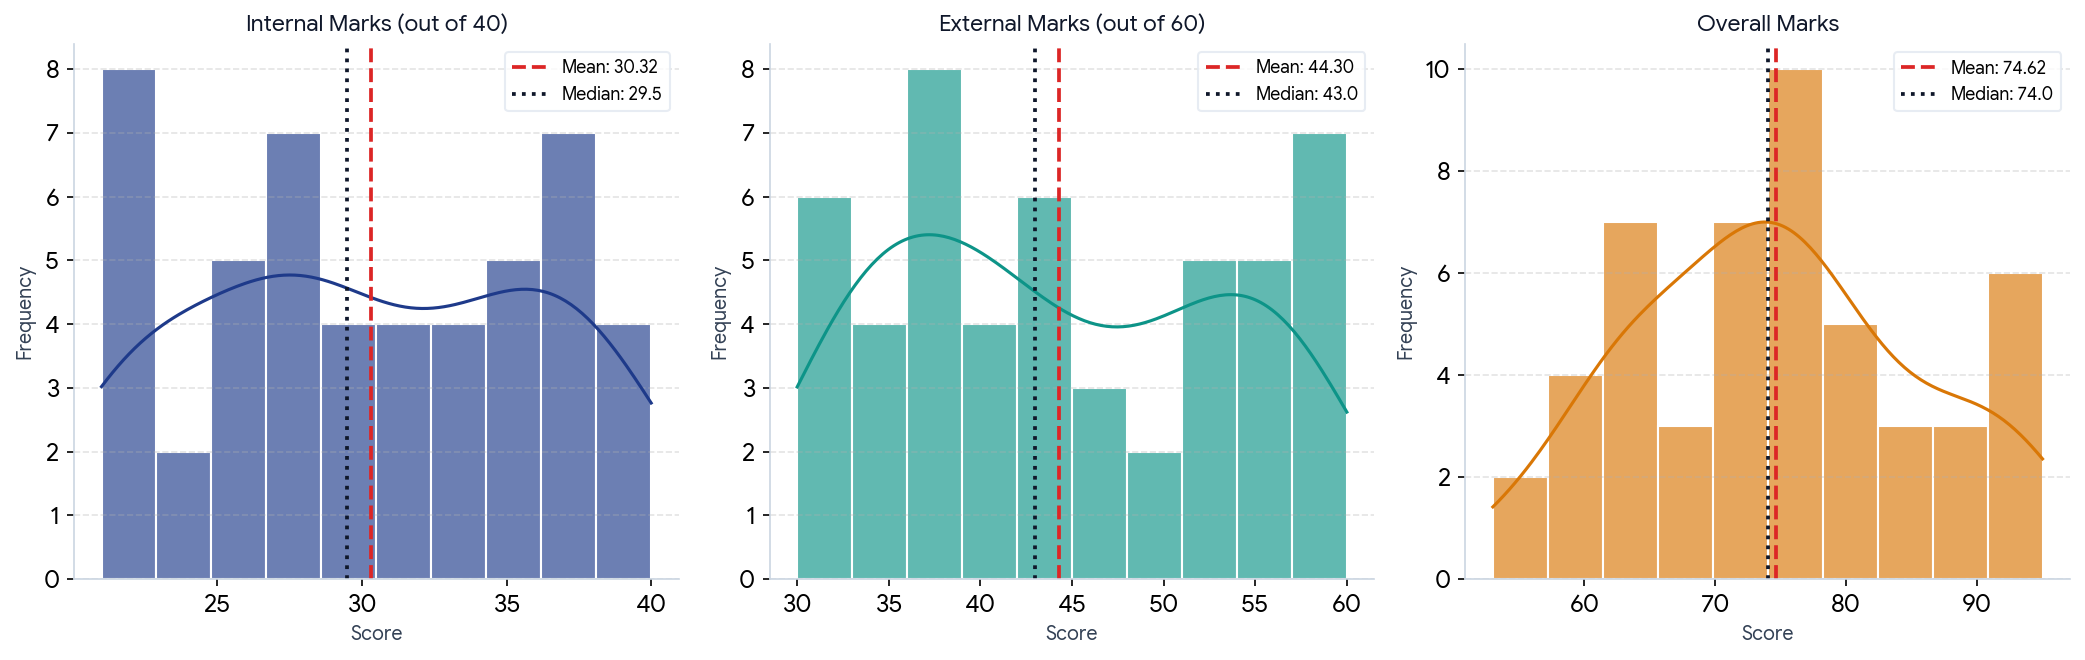

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
metrics = [
    ('Internal Marks (out of 40)', '#1E3A8A'),
    ('External Marks (out of 60)', '#0D9488'),
    ('Overall Marks', '#D97706')
]
for ax, (col, color) in zip(axes, metrics):
    sns.histplot(df[col], bins=10, kde=True, ax=ax, color=color, alpha=0.65, edgecolor='white')
    ax.axvline(df[col].mean(), color='#DC2626', linestyle='--', linewidth=1.8, label=f'Mean: {df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='#0F172A', linestyle=':', linewidth=1.8, label=f'Median: {df[col].median():.1f}')
    ax.set_title(col, fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Academic Field Comparative Analysis (BBA vs. BCA vs. BTech)
Comparing score distributions and normalized assessment percentages across the three academic programs.

      Internal Marks (out of 40)                      External Marks (out of 60)                      Overall Marks                      Internal_Pct                 External_Pct                
                           count   mean median   std                      count   mean median    std         count   mean median    std        count   mean median    std        count   mean median    std
Field                                                                                                                                                                                           
BBA                           23  30.83   29.0  6.20                         23  45.87   43.0   8.77            23  76.70   76.0  11.12           23  77.07   72.5  15.50           23  76.45   71.67  14.61
BCA                           16  30.19   28.5  5.74                         16  42.75   42.0   8.59            16  72.94   72.5   8.78           16  75.47   71.25 14.35           16  71.25   70.00  14.3

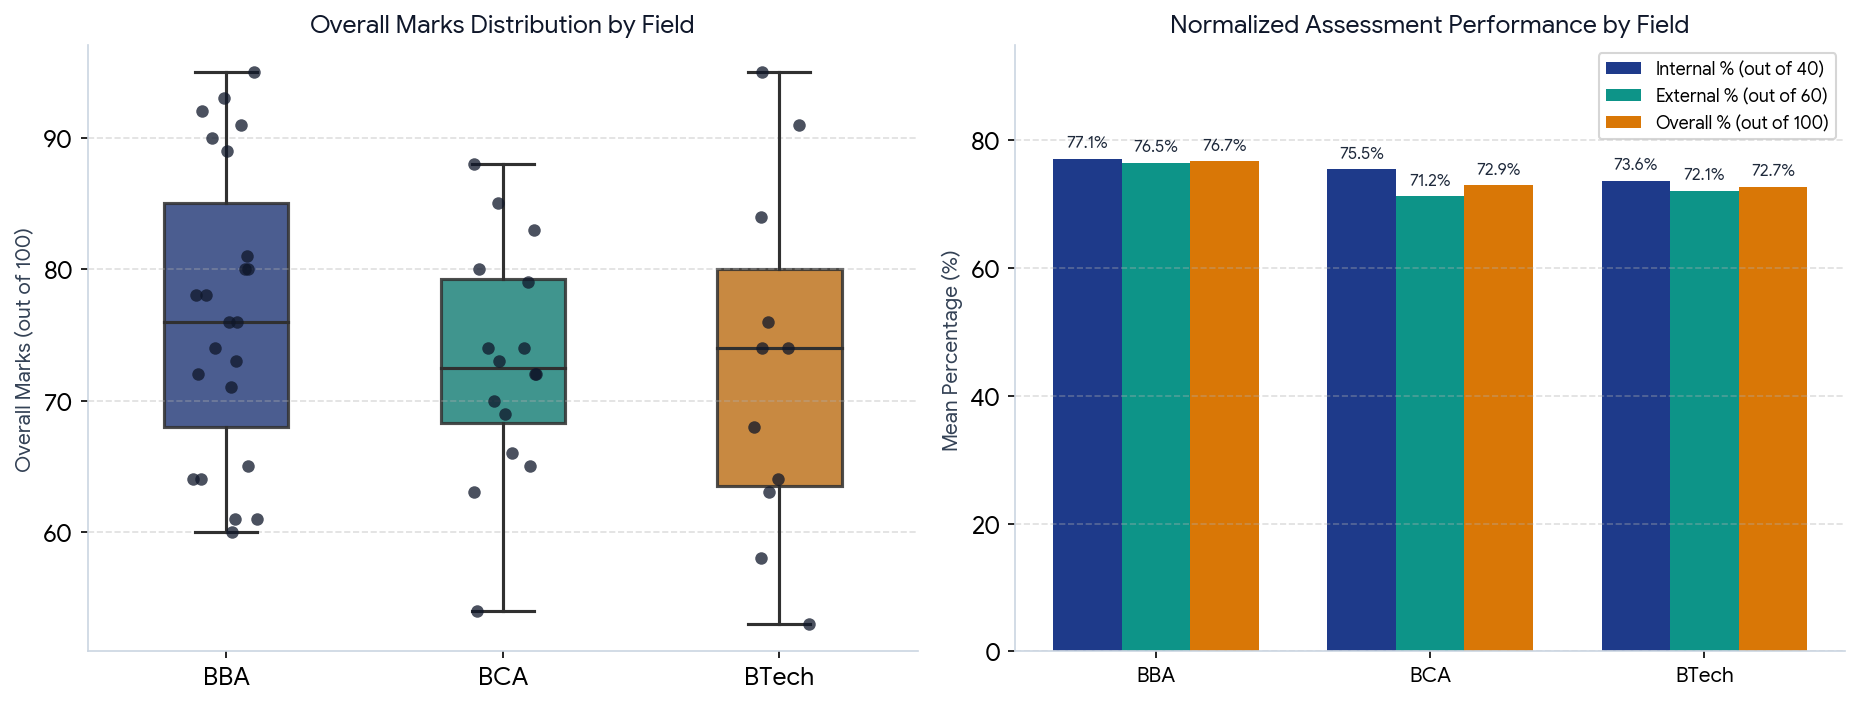

In [ ]:
field_summary = df.groupby('Field')[['Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks', 'Internal_Pct', 'External_Pct']].agg(['count', 'mean', 'median', 'std'])
print(field_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
order = ['BBA', 'BCA', 'BTech']
sns.boxplot(data=df, x='Field', y='Overall Marks', order=order, palette=PALETTE, width=0.45, ax=axes[0])
sns.stripplot(data=df, x='Field', y='Overall Marks', order=order, color='#0F172A', size=6, jitter=0.12, ax=axes[0])
axes[0].set_title('Overall Marks Distribution by Field', fontweight='bold')

field_pct = df.groupby('Field')[['Internal_Pct', 'External_Pct', 'Overall Marks']].mean().reindex(order)
field_pct.plot(kind='bar', ax=axes[1], color=['#1E3A8A', '#0D9488', '#D97706'], rot=0)
axes[1].set_title('Normalized Assessment Performance by Field', fontweight='bold')
axes[1].set_ylabel('Mean Percentage (%)')
axes[1].set_ylim(0, 95)
plt.tight_layout()
plt.show()

## 7. Correlation Analysis & Score Drivers
- **Internal vs. External Independence:** Pearson $r = -0.023$ ($p = 0.874$), confirming virtually zero linear correlation between internal coursework scores and external exam scores.
- **Primary Driver of Overall Marks:** Because External Marks account for **60%** of the total score and exhibit a higher standard deviation ($9.22$ vs. $6.05$), External Marks correlate far more strongly with Overall Marks ($r = 0.832$) than Internal Marks ($r = 0.535$).
- **Age Effect:** Age exhibits negligible correlation with Overall Marks ($r = 0.079$).

                               Age  Internal Marks (out of 40)  External Marks (out of 60)  Overall Marks
Age                         1.0000                      0.1976                     -0.0363         0.0789
Internal Marks (out of 40)  0.1976                      1.0000                     -0.0230         0.5348
External Marks (out of 60) -0.0363                     -0.0230                      1.0000         0.8324
Overall Marks               0.0789                      0.5348                      0.8324         1.0000

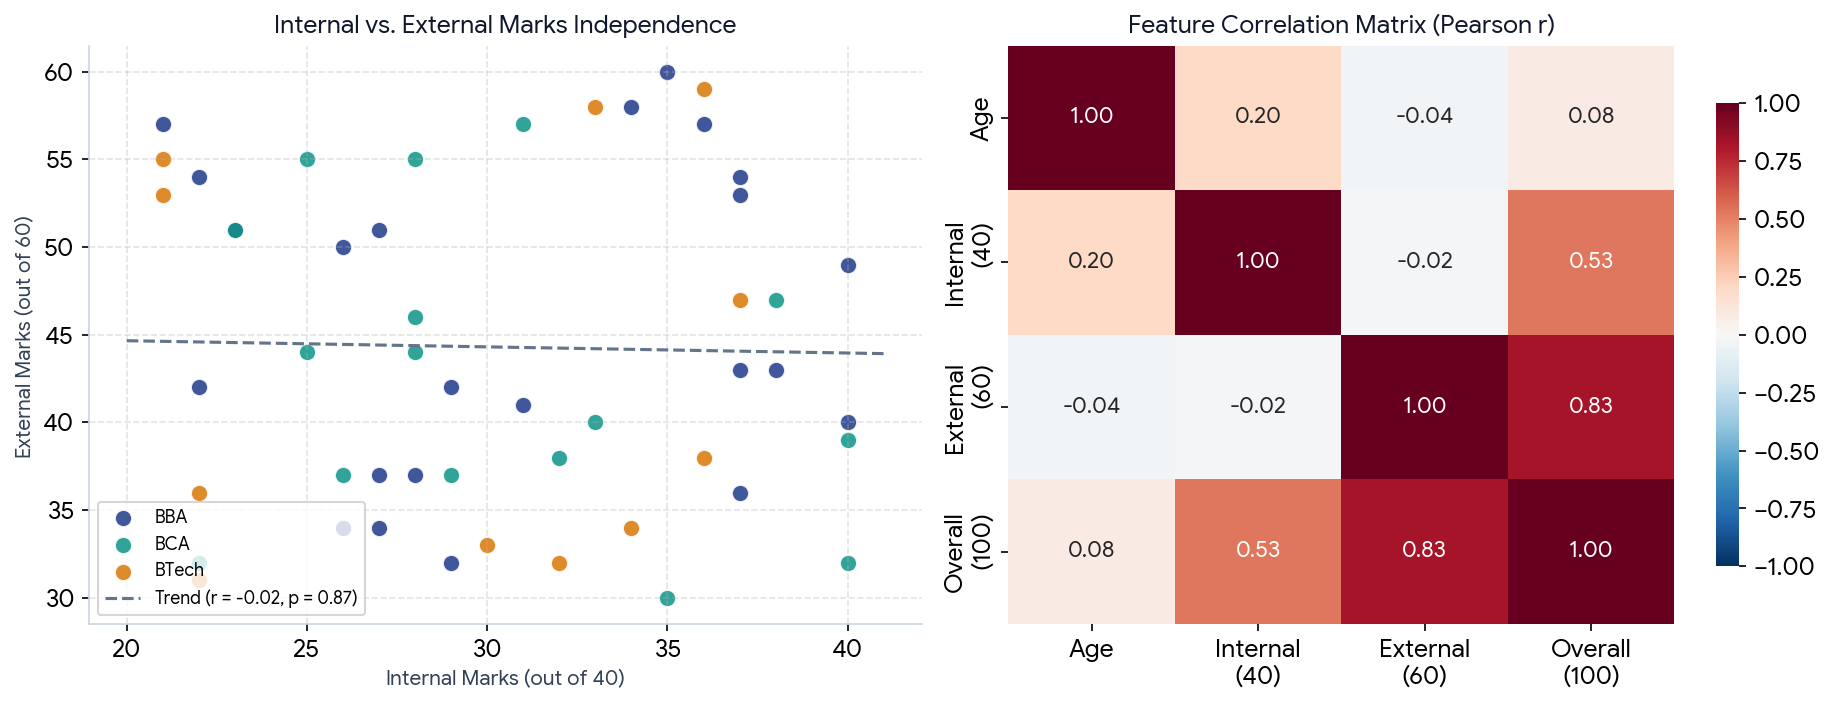

In [ ]:
corr_cols = ['Age', 'Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks']
corr_matrix = df[corr_cols].corr()
print(corr_matrix.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for f in ['BBA', 'BCA', 'BTech']:
    sub = df[df['Field'] == f]
    axes[0].scatter(sub['Internal Marks (out of 40)'], sub['External Marks (out of 60)'], label=f, color=PALETTE[f], s=65)
axes[0].set_title('Internal vs. External Marks Independence', fontweight='bold')
axes[0].set_xlabel('Internal Marks (out of 40)')
axes[0].set_ylabel('External Marks (out of 60)')
axes[0].legend()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=axes[1])
axes[1].set_title('Feature Correlation Matrix (Pearson r)', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Subject-Level & Age-Group Granular Analysis
The cohort spans **17 distinct subjects** (with *Data Structures* appearing in both BCA and BTech, yielding 18 Field-Subject pairs). Note that small sample sizes per subject ($n = 1$ to $5$) create wide apparent spreads (e.g., BTech *Thermodynamics* averages 93.0 across $n=2$, whereas BTech *Data Structures* has $n=1$ at 64.0).

                           count   mean  min  max
Field Subject                                    
BTech Thermodynamics           2  93.00   91   95
BBA   Accounting               5  83.80   71   95
      Finance                  4  80.50   61   93
BCA   Python                   4  78.75   63   88
BBA   Business Law             2  77.00   74   80
      Operations               4  76.50   61   89
BCA   Operating Systems        4  75.25   73   80
BTech Machine Learning         1  74.00   74   74
BBA   Marketing                5  72.20   64   81
BCA   Web Design               3  70.33   69   72
BTech Networks                 4  69.00   53   84
BCA   Databases                2  68.50   65   72
      Java                     2  68.50   54   83
BTech Digital Electronics      1  68.00   68   68
BBA   HR Management            3  67.33   60   78
BCA   Data Structures          1  66.00   66   66
BTech AI                       2  66.00   58   74
      Data Structures          1  64.00   64   64

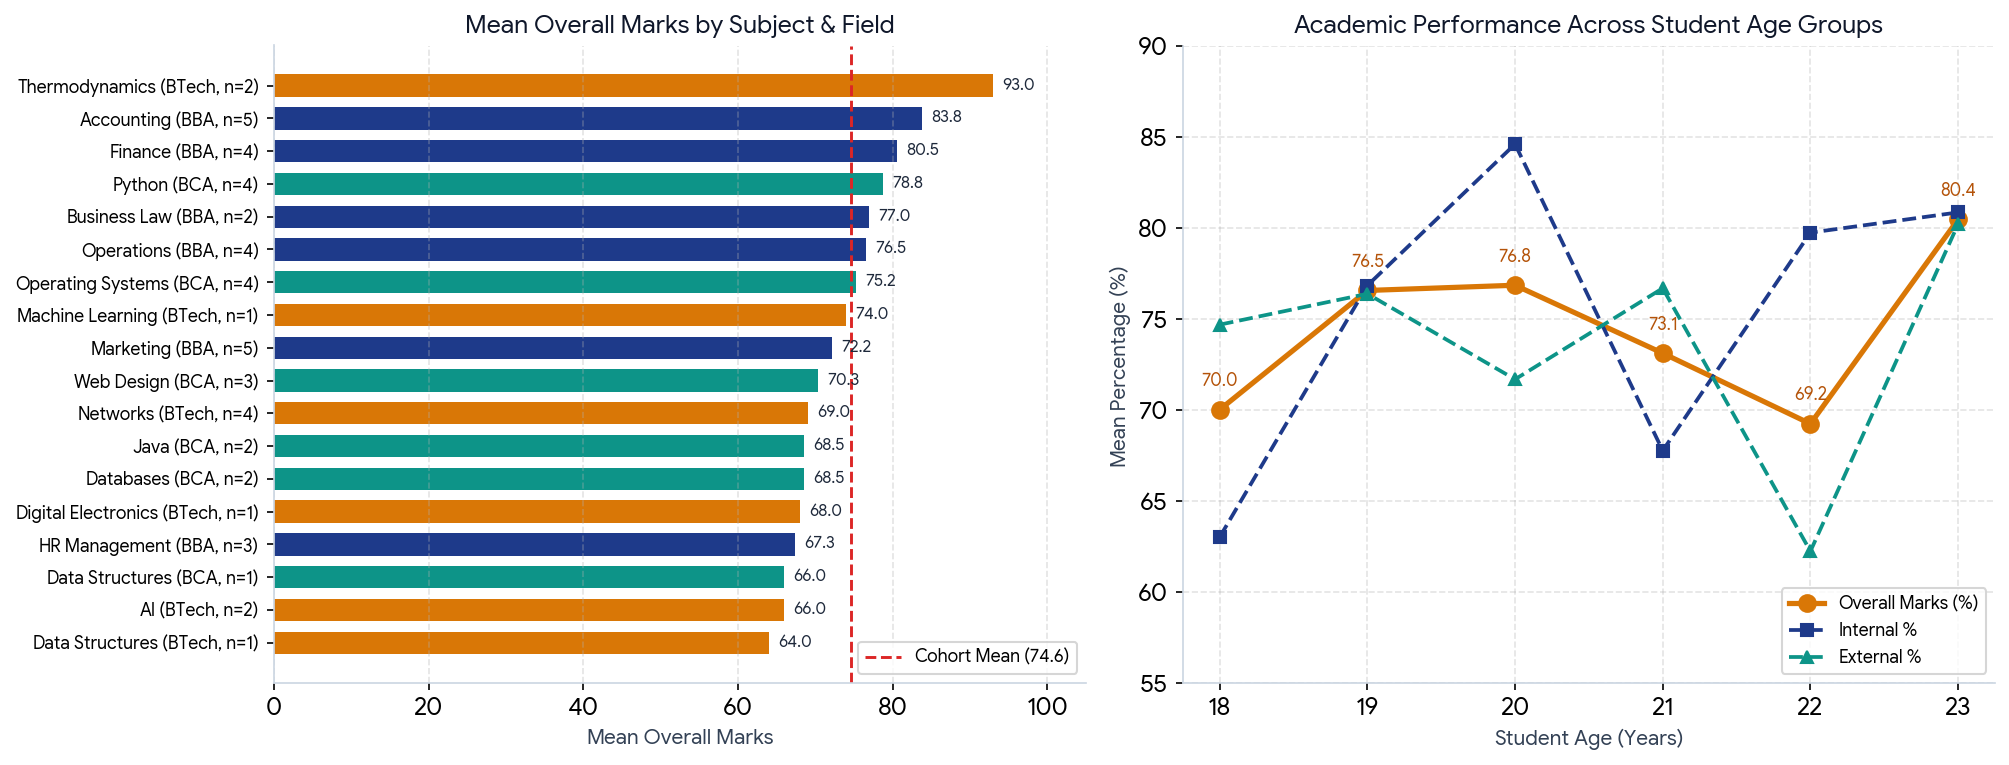

In [ ]:
subj_summary = df.groupby(['Field', 'Subject'])['Overall Marks'].agg(['count', 'mean', 'min', 'max']).sort_values('mean', ascending=False)
print(subj_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
subj_plot = subj_summary.reset_index().sort_values('mean', ascending=True)
subj_plot['Label'] = subj_plot['Subject'] + ' (' + subj_plot['Field'] + ', n=' + subj_plot['count'].astype(str) + ')'
axes[0].barh(subj_plot['Label'], subj_plot['mean'], color=[PALETTE[f] for f in subj_plot['Field']])
axes[0].axvline(df['Overall Marks'].mean(), color='#DC2626', linestyle='--', label='Cohort Mean (74.6)')
axes[0].set_title('Mean Overall Marks by Subject & Field', fontweight='bold')
axes[0].legend()

age_stats = df.groupby('Age')[['Internal_Pct', 'External_Pct', 'Overall Marks']].mean().reset_index()
axes[1].plot(age_stats['Age'], age_stats['Overall Marks'], marker='o', linewidth=2.5, color='#D97706', label='Overall Marks (%)')
axes[1].plot(age_stats['Age'], age_stats['Internal_Pct'], marker='s', linestyle='--', color='#1E3A8A', label='Internal %')
axes[1].plot(age_stats['Age'], age_stats['External_Pct'], marker='^', linestyle='--', color='#0D9488', label='External %')
axes[1].set_title('Academic Performance Across Student Age Groups', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Top Performers, At-Risk Students & Assessment Parity
- **Top Performers:** Muskan (BBA, Accounting) and Abhishek (BTech, Thermodynamics) tie at **95/100**. All Top 5 students score >=91 (Grade A+).
- **At-Risk Cohort:** Pooja (BTech, Networks, 53), Bhavna (BCA, Java, 54), and Varun (BTech, AI, 58) score below 60 (Grade D) due to simultaneous weak internal (55%) and external (51.7%–60.0%) scores.
- **Internal vs. External Parity:** Students frequently exhibit wide divergence between internal coursework and final exams (e.g., some score >90% internally but <65% externally, and vice versa), highlighting the need for early mid-semester intervention.

--- TOP 5 STUDENTS ---
        Name  Age  Field         Subject  Internal Marks (out of 40)  External Marks (out of 60)  Overall Marks
43    Muskan   19    BBA      Accounting                          35                          60             95
38  Abhishek   19  BTech  Thermodynamics                          36                          59             95
44     Kunal   19    BBA         Finance                          36                          57             93
47     Aarti   23    BBA         Finance                          34                          58             92
45    Sakshi   21    BBA      Accounting                          37                          54             91

--- BOTTOM 5 STUDENTS ---
      Name  Age  Field        Subject  Internal Marks (out of 40)  External Marks (out of 60)  Overall Marks
13   Pooja   22  BTech       Networks                          22                          31             53
41  Bhavna   19    BCA           Java                       

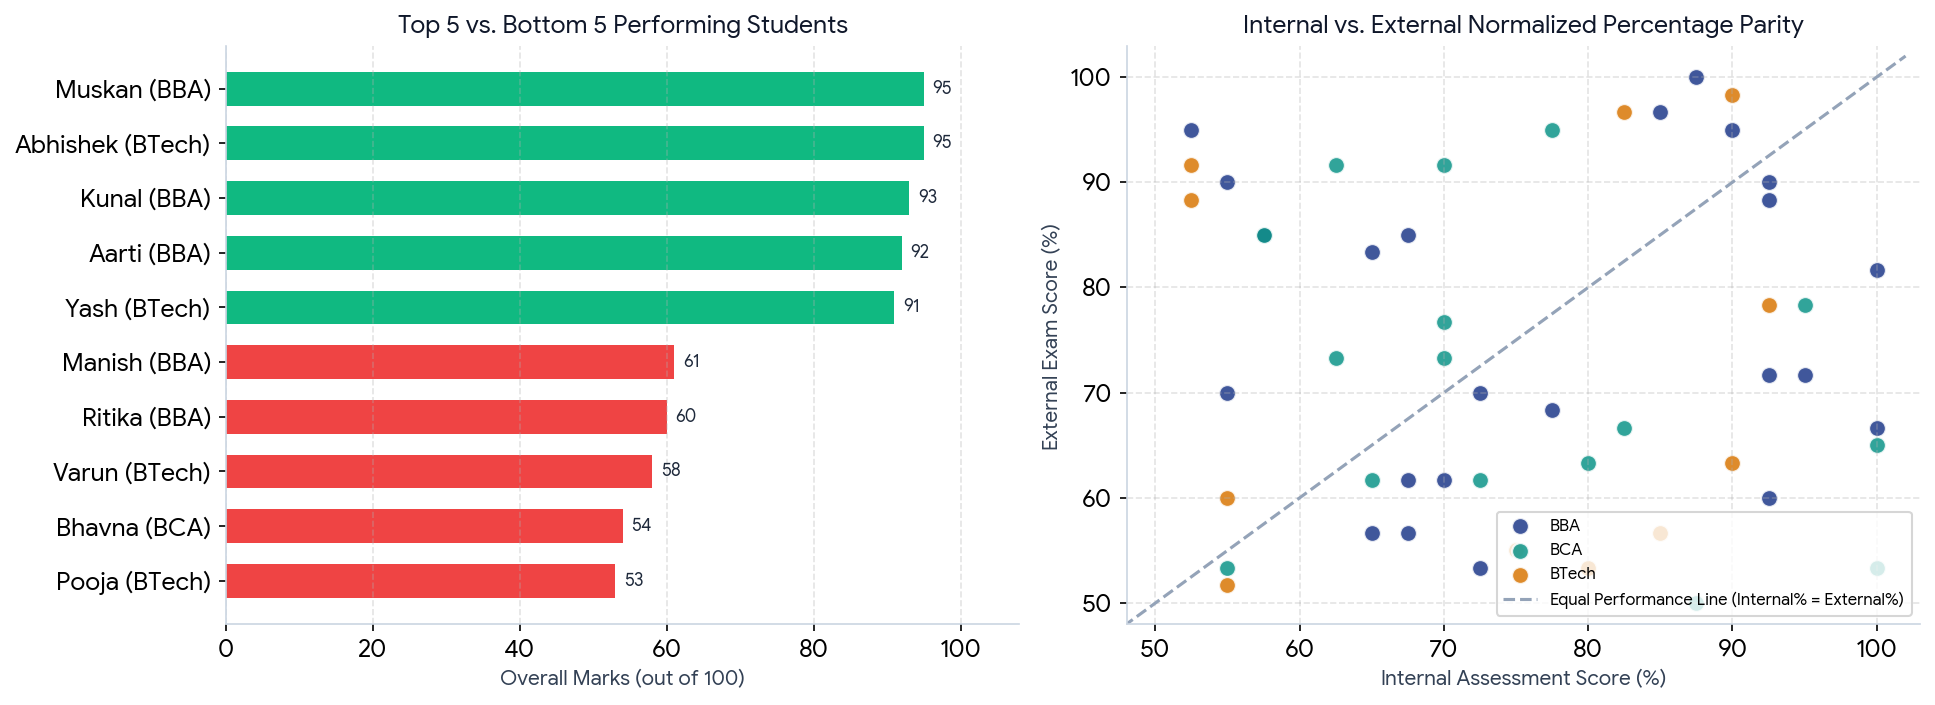

In [ ]:
print('--- TOP 5 STUDENTS ---')
print(df.nlargest(5, 'Overall Marks')[['Name', 'Age', 'Field', 'Subject', 'Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks']])
print('\n--- BOTTOM 5 STUDENTS ---')
print(df.nsmallest(5, 'Overall Marks')[['Name', 'Age', 'Field', 'Subject', 'Internal Marks (out of 40)', 'External Marks (out of 60)', 'Overall Marks']])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
top_bot = pd.concat([df.nlargest(5, 'Overall Marks'), df.nsmallest(5, 'Overall Marks')]).sort_values('Overall Marks')
top_bot['Label'] = top_bot['Name'] + ' (' + top_bot['Field'] + ')'
axes[0].barh(top_bot['Label'], top_bot['Overall Marks'], color=['#EF4444' if m < 65 else '#10B981' for m in top_bot['Overall Marks']])
axes[0].set_title('Top 5 vs. Bottom 5 Performing Students', fontweight='bold')

for f in ['BBA', 'BCA', 'BTech']:
    sub = df[df['Field'] == f]
    axes[1].scatter(sub['Internal_Pct'], sub['External_Pct'], label=f, color=PALETTE[f], s=65)
axes[1].plot([45, 102], [45, 102], color='#94A3B8', linestyle='--', label='Equal Performance Line')
axes[1].set_title('Internal vs. External Normalized Percentage Parity', fontweight='bold')
axes[1].set_xlabel('Internal Assessment Score (%)')
axes[1].set_ylabel('External Exam Score (%)')
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Statistical Hypothesis Testing & Conclusions
We conduct formal hypothesis tests to determine whether observed group differences are statistically significant or consistent with random sampling variation.

In [ ]:
# 1. One-Way ANOVA: Overall Marks across BBA, BCA, BTech
f_stat, p_anova = stats.f_oneway(
    df[df['Field']=='BBA']['Overall Marks'],
    df[df['Field']=='BCA']['Overall Marks'],
    df[df['Field']=='BTech']['Overall Marks']
)

# 2. Paired t-test: Normalized Internal % vs External %
t_stat, p_paired = stats.ttest_rel(df['Internal_Pct'], df['External_Pct'])

# 3. Shapiro-Wilk Normality Test on Overall Marks
w_stat, p_sw = stats.shapiro(df['Overall Marks'])

print(f'1. One-Way ANOVA (Field -> Overall Marks): F = {f_stat:.4f}, p = {p_anova:.4f} (No significant difference across fields)')
print(f'2. Paired t-test (Internal % vs External %): t = {t_stat:.4f}, p = {p_paired:.4f} (Grading scales are well-calibrated)')
print(f'3. Shapiro-Wilk Test (Overall Marks Normality): W = {w_stat:.4f}, p = {p_sw:.4f} (Consistent with normal distribution)')

1. One-Way ANOVA (Field -> Overall Marks): F = 0.7650, p = 0.4710 (No significant difference across fields)
2. Paired t-test (Internal % vs External %): t = 0.6379, p = 0.5265 (Grading scales are well-calibrated)
3. Shapiro-Wilk Test (Overall Marks Normality): W = 0.9738, p = 0.3271 (Consistent with normal distribution)

### Executive Summary of Findings
1. **Strong Overall Achievement:** 100% pass rate with a cohort mean of **74.62 / 100** (SD = 10.91) and 32% of students achieving Grade A or A+.
2. **Program Parity:** Although BBA holds the highest nominal mean (**76.70**) compared to BCA (**72.94**) and BTech (**72.73**), One-Way ANOVA ($p = 0.471$) confirms differences across disciplines are not statistically significant.
3. **External Exams Drive Variance:** External marks (60% weight) correlate strongly with final scores ($r = 0.832$), while internal and external scores operate independently ($r = -0.023$).
4. **Targeted Support Opportunities:** Students scoring below 60% in internal assessments (e.g., Pooja, Bhavna, Varun) should be flagged at mid-semester for academic mentoring before external exams.